# Reto 1 · Exploración y calidad de datos

**Clustering the Star — Mercedes-Benz · III Malackathon 2026**

Objetivo: entender la base de clientes antes de segmentarla. En este notebook:

1. Carga y **granularidad** del dataset (¿qué es una fila?)
2. Identificación y **exclusión justificada** de metadatos e identificadores
3. **Valores nulos** e **inconsistencias**, con propuesta de tratamiento
4. **Estadísticas descriptivas** y **distribuciones** de las variables clave
5. Resumen de hallazgos y conclusiones

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

DATA = "datos_reto_mercedes_benz_malackathon.csv"  # CSV en la raíz del repositorio
df = pd.read_csv(DATA, low_memory=False)
df.shape

(302850, 39)

## 1. Estructura y granularidad

In [2]:
df.head(3).T

,0,1,2
Unnamed: 0,0,1,2
client_id,000144e39c02702f821f69beeb7036f40cf8505051050f...,000144e39c02702f821f69beeb7036f40cf8505051050f...,0002f3a9f4483f444b7665eba96822dad2f1dcfe8d0fab...
vehicle_id,db75a50f450de43f5f7a94d2a05b605fdc1a5d84913ba6...,e1ddd663e780ffc6dc8194aeb1189a2176ca796d5d3897...,716e4f639ce69defa3b9ce202848cdca612814e7d0dc47...
age_range,35-44,35-44,25-34
gender_derived,female,female,male
model_series,177,206,213
vehicle_type,A 180 d,C 200 d,AMG E 63 S 4MATIC+
model_class,A-Class,C-Class,E-Class
product_group,P,P,P
engine_concept,NaN,NaN,COMBUSTION


In [3]:
df.dtypes.value_counts(), df.dtypes

(str        17
 float64    14
 int64       4
 bool        4
 Name: count, dtype: int64,
 Unnamed: 0                               int64
 client_id                                  str
 vehicle_id                                 str
 age_range                                  str
 gender_derived                             str
 model_series                             int64
 vehicle_type                               str
 model_class                                str
 product_group                              str
 engine_concept                             str
 country_code                               str
 fuel_type                                  str
 date_of_first_registration                 str
 is_current_vehicle                        bool
 role                                       str
 role_type                                  str
 months_as_mb_customer                  float64
 currently_connected_vehicles             int64
 finance_leasing_status                     str


In [4]:
n_rows = len(df)
n_clients = df["client_id"].nunique()
n_vehicles = df["vehicle_id"].nunique()
pd.Series({"filas": n_rows, "clientes únicos": n_clients, "vehículos únicos": n_vehicles,
           "filas duplicadas (cliente, vehículo)": df.duplicated(["client_id", "vehicle_id"]).sum(),
           "filas duplicadas completas": df.drop(columns=df.columns[0]).duplicated().sum()})

filas                                   302850
clientes únicos                         173456
vehículos únicos                        244519
filas duplicadas (cliente, vehículo)         0
filas duplicadas completas                   0
dtype: int64

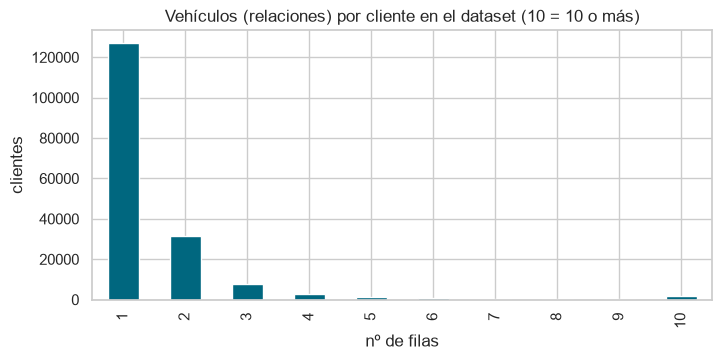

count   173,456.00
mean          1.75
std           5.51
min           1.00
25%           1.00
50%           1.00
75%           2.00
max         561.00
dtype: float64

In [5]:
veh_por_cliente = df.groupby("client_id").size()
ax = veh_por_cliente.clip(upper=10).value_counts().sort_index().plot.bar(figsize=(8, 3.5), color="#00677F")
ax.set(title="Vehículos (relaciones) por cliente en el dataset (10 = 10 o más)", xlabel="nº de filas", ylabel="clientes")
plt.show()
veh_por_cliente.describe()

In [6]:
# Cola larga: clientes con muchísimas relaciones (comportamiento de flota aunque figuren como B2C)
grandes = veh_por_cliente[veh_por_cliente > 10]
pd.Series({"clientes con >10 relaciones": len(grandes),
           "% de clientes": len(grandes) / n_clients * 100,
           "filas que acumulan": grandes.sum(),
           "% de filas": grandes.sum() / n_rows * 100,
           "máximo de relaciones de un cliente": veh_por_cliente.max()}).round(2)

clientes con >10 relaciones           1,706.00
% de clientes                             0.98
filas que acumulan                   60,530.00
% de filas                               19.99
máximo de relaciones de un cliente      561.00
dtype: float64

**Cada fila es una relación cliente–vehículo**, no un cliente. Un cliente aparece tantas veces como
vehículos ha tenido vinculados (actuales o pasados). Como el reto pide segmentar **clientes**, en el
Reto 2 agregaremos a **una fila por cliente**.

Comprobamos que los atributos propios del cliente son constantes entre sus filas (si lo son, la
agregación es directa y no hay conflictos que resolver):

In [7]:
atributos_cliente = ["age_range", "gender_derived", "country_code", "months_as_mb_customer",
                     "currently_connected_vehicles", "finance_leasing_status",
                     "consent_phone_communication_channel", "consent_epost_communication_channel",
                     "consent_post_communication_channel", "zipcode",
                     "purchasing_power_per_inhabitant_eur"]
(df.groupby("client_id")[atributos_cliente].nunique(dropna=False) > 1).sum().rename("clientes con >1 valor")

age_range                              0
gender_derived                         0
country_code                           0
months_as_mb_customer                  0
currently_connected_vehicles           0
finance_leasing_status                 0
consent_phone_communication_channel    0
consent_epost_communication_channel    0
consent_post_communication_channel     0
zipcode                                0
purchasing_power_per_inhabitant_eur    0
Name: clientes con >1 valor, dtype: int64

## 2. Columnas de metadatos e identificadores

| Columna | Decisión | Motivo |
|---|---|---|
| `Unnamed: 0` | **Excluir** | Índice exportado del DataFrame original; no es información |
| `client_id` | **Excluir como feature** | Hash identificador. Solo se usa como clave para agregar por cliente |
| `vehicle_id` | **Excluir** | Hash identificador del vehículo; solo sirve para contar vehículos |
| `zipcode` | **Excluir como feature** | Identificador geográfico de alta cardinalidad; su información útil ya está en las variables socioeconómicas del CP |
| `model_series` | **Excluir** | Código interno redundante con `model_class` (ver abajo) |
| `vehicle_type` | **Excluir como feature** | Denominación comercial con cientos de valores; `model_class` + `engine_concept` resumen lo relevante |
| `trip_distance_mode`, `speed_mode` | **Excluir** | Modas guardadas como texto, redundantes con media/mediana |
| `*_all_counter` | **Excluir como feature** | Son contadores técnicos de cuántas mediciones hay, no comportamiento del cliente |

In [8]:
card = df.nunique().sort_values(ascending=False).rename("valores distintos").to_frame()
card["% nulos"] = df.isna().mean().mul(100).round(1)
card

,valores distintos,% nulos
Unnamed: 0,302850,0.00
vehicle_id,244519,0.00
client_id,173456,0.00
speed_all_counter,117441,59.80
operating_hours_total,80943,57.60
trip_distance_all_counter,10780,59.40
speed_average,8248,60.20
trip_distance_average,5476,61.40
date_of_first_registration,5316,1.40
purchasing_power_per_household_eur,5035,6.30


In [9]:
# model_series -> model_class: ¿cuántas clases distintas tiene cada serie?
df.groupby("model_series")["model_class"].nunique().value_counts().rename("series según nº de clases")

model_class
1    82
0     6
Name: series según nº de clases, dtype: int64

In [10]:
# Los nulos de model_class: ¿qué vehículos son?
df.loc[df["model_class"].isna(), "vehicle_type"].value_counts().head(10)

vehicle_type
GLC 400 4MATIC           1643
GLB 350 4MATIC            732
CLA 220 4MATIC            278
GLB 250+                  220
GLB 220 4MATIC            130
CLA 200 4MATIC             98
CLA 180                    76
C 400 4MATIC electric      73
GLB 200 4MATIC             37
CLA 200                    37
Name: count, dtype: int64

## 3. Valores nulos

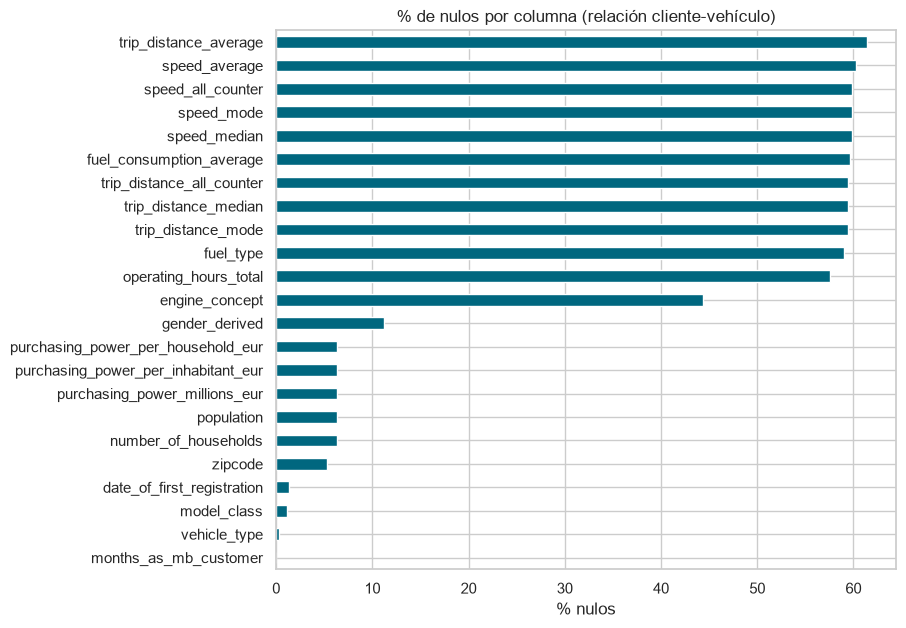

In [11]:
nulos = df.isna().mean().mul(100).sort_values(ascending=False)
nulos = nulos[nulos > 0]
ax = nulos.plot.barh(figsize=(8, 7), color="#00677F")
ax.invert_yaxis()
ax.set(title="% de nulos por columna (relación cliente-vehículo)", xlabel="% nulos")
plt.show()

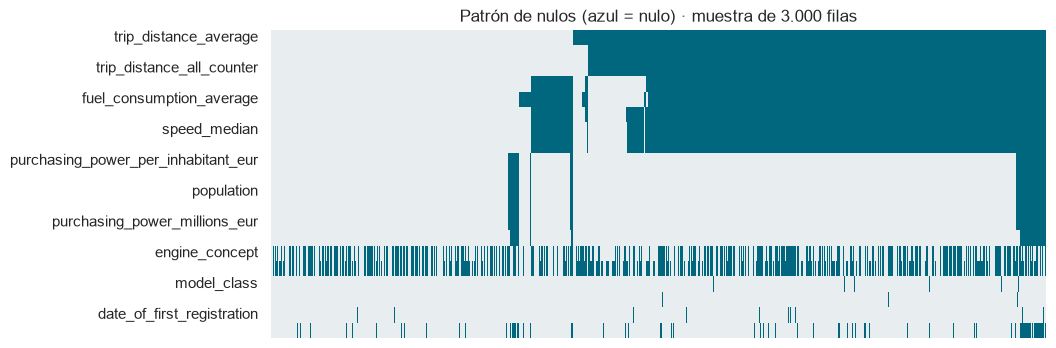

In [12]:
# ¿Los nulos de telemetría van en bloque? Matriz de patrones sobre una muestra
cols_tel = ["trip_distance_average", "trip_distance_median", "trip_distance_all_counter",
            "operating_hours_total", "fuel_consumption_average", "speed_average",
            "speed_median", "speed_all_counter"]
cols_socio = ["purchasing_power_per_inhabitant_eur", "purchasing_power_per_household_eur",
              "population", "number_of_households", "purchasing_power_millions_eur", "zipcode"]
cols_motor = ["engine_concept", "fuel_type", "model_class", "vehicle_type", "date_of_first_registration", "gender_derived"]
muestra = df.sample(3000, random_state=0)[cols_tel + cols_socio + cols_motor].isna()
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(muestra.sort_values(cols_tel + cols_socio).T, cbar=False, cmap=["#e8eef0", "#00677F"], xticklabels=False, ax=ax)
ax.set(title="Patrón de nulos (azul = nulo) · muestra de 3.000 filas")
plt.show()

In [13]:
# ¿Tienen telemetría los vehículos actuales o los pasados?
df["tiene_telemetria"] = df[cols_tel].notna().any(axis=1)
pd.crosstab(df["is_current_vehicle"], df["tiene_telemetria"], normalize="index").mul(100).round(1)

tiene_telemetria,False,True
is_current_vehicle,,
False,66.60,33.40
True,41.70,58.30


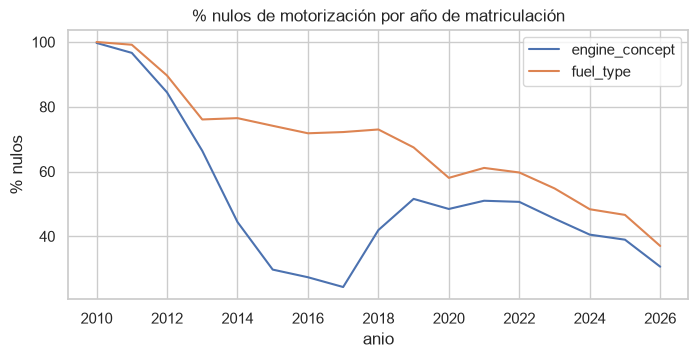

In [14]:
# Nulos de engine_concept / fuel_type según antigüedad de matriculación
reg = pd.to_datetime(df["date_of_first_registration"], errors="coerce")
(df.assign(anio=reg.dt.year)
   .groupby("anio")[["engine_concept", "fuel_type"]]
   .apply(lambda g: g.isna().mean() * 100)
   .loc[2010:]
   .plot(figsize=(8, 3.5), title="% nulos de motorización por año de matriculación", ylabel="% nulos"))
plt.show()

## 4. Inconsistencias y valores extremos

In [15]:
FECHA_REF = reg.max()  # fecha de referencia del extracto: la matriculación más reciente
checks = {
    "fecha de matriculación futura (> fecha de referencia)": (reg > FECHA_REF).sum(),
    "fecha de matriculación < 1990": (reg < "1990-01-01").sum(),
    "fecha no parseable (no nula)": (reg.isna() & df["date_of_first_registration"].notna()).sum(),
    "months_as_mb_customer nulo": df["months_as_mb_customer"].isna().sum(),
    "months_as_mb_customer = 0 (cliente nuevo)": (df["months_as_mb_customer"] == 0).sum(),
    "population = 0 con poder adquisitivo informado": ((df["population"] == 0) & df["purchasing_power_per_inhabitant_eur"].notna()).sum(),
    "currently_connected_vehicles = 0": (df["currently_connected_vehicles"] == 0).sum(),
    "speed_average > 200 km/h": (df["speed_average"] > 200).sum(),
    "fuel_consumption_average > 30": (df["fuel_consumption_average"] > 30).sum(),
    "ELECTRIC con consumo de combustible > 0": ((df["engine_concept"] == "ELECTRIC") & (df["fuel_consumption_average"] > 0)).sum(),
    "role_type B2B con role != DRIVER": ((df["role_type"] == "B2B") & (df["role"] != "DRIVER")).sum(),
}
print("Fecha de referencia:", FECHA_REF.date())
pd.Series(checks, name="filas")

Fecha de referencia: 2026-10-02


fecha de matriculación futura (> fecha de referencia)        0
fecha de matriculación < 1990                                2
fecha no parseable (no nula)                                 0
months_as_mb_customer nulo                                   4
months_as_mb_customer = 0 (cliente nuevo)                 8634
population = 0 con poder adquisitivo informado               0
currently_connected_vehicles = 0                         31751
speed_average > 200 km/h                                    10
fuel_consumption_average > 30                              401
ELECTRIC con consumo de combustible > 0                      0
role_type B2B con role != DRIVER                             0
Name: filas, dtype: int64

In [16]:
# Coherencia: vehículos actuales en el dataset vs. currently_connected_vehicles declarado
cli = df.groupby("client_id").agg(actuales_en_datos=("is_current_vehicle", "sum"),
                                  declarados=("currently_connected_vehicles", "first"))
cli["diferencia"] = cli["declarados"] - cli["actuales_en_datos"]
print(f"Clientes donde coincide: {(cli['diferencia'] == 0).mean():.1%}")
cli["diferencia"].clip(-5, 5).value_counts().sort_index()

Clientes donde coincide: 100.0%


diferencia
0    173452
1         4
Name: count, dtype: int64

In [17]:
# Coherencia engine_concept vs fuel_type
pd.crosstab(df["engine_concept"].fillna("(nulo)"), df["fuel_type"].fillna("(nulo)"))

fuel_type,(nulo),DIESEL,"DIESEL,ELECTRIC",ELECTRIC,PETROL,"PETROL,ELECTRIC",PETROL_PLUS,"PETROL_PLUS,ELECTRIC"
engine_concept,,,,,,,,
(nulo),134390,0,0,0,0,0,0,0
COMBUSTION,43915,28475,0,0,14422,0,11612,0
ELECTRIC,0,0,0,20944,0,0,0,0
MILD_HYBRID,29,7418,0,0,17946,0,2362,0
PLUGIN_HYBRID,411,0,8604,0,0,7371,0,4951


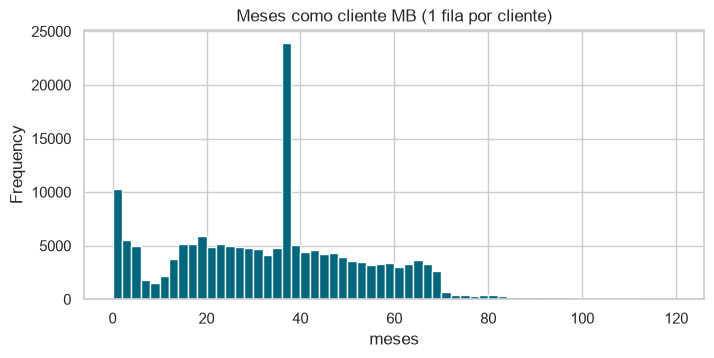

In [18]:
# Antigüedad como cliente (el máximo es 120 meses = 10 años, pero solo lo alcanzan unos pocos clientes)
ax = df.drop_duplicates("client_id")["months_as_mb_customer"].plot.hist(bins=60, figsize=(8, 3.5), color="#00677F")
ax.set(title="Meses como cliente MB (1 fila por cliente)", xlabel="meses")
plt.show()

## 5. Estadísticas descriptivas y distribuciones

Para describir **clientes** (no relaciones) usamos una fila por cliente para los atributos de
cliente, y todas las filas para los atributos de vehículo.

In [19]:
clientes = df.drop_duplicates("client_id")
num_cliente = ["months_as_mb_customer", "currently_connected_vehicles",
               "purchasing_power_per_inhabitant_eur", "purchasing_power_per_household_eur",
               "population", "number_of_households", "purchasing_power_millions_eur"]
clientes[num_cliente].describe(percentiles=[.05, .25, .5, .75, .95]).T

,count,mean,std,min,5%,25%,50%,75%,95%,max
months_as_mb_customer,"173,454.00",33.90,20.73,0.00,1.00,18.00,36.00,47.00,67.00,120.00
currently_connected_vehicles,"173,456.00",1.04,0.88,0.00,0.00,1.00,1.00,1.00,2.00,21.00
purchasing_power_per_inhabitant_eur,"158,097.00","47,189.33","17,304.08","19,701.53","27,169.71","32,072.80","46,753.32","54,750.58","77,483.13","148,353.74"
purchasing_power_per_household_eur,"158,097.00","106,347.13","41,929.36","45,087.34","58,381.26","72,810.07","103,738.42","123,410.83","184,202.62","342,497.95"
population,"158,140.00","20,066.46","37,090.01",0.00,"1,011.00","3,132.00","7,364.00","18,501.00","101,714.00","220,794.00"
number_of_households,"158,140.00","9,531.86","17,902.72",0.00,432.00,"1,336.00","3,278.00","8,920.00","50,850.00","102,998.00"
purchasing_power_millions_eur,"158,097.00",756.28,"1,045.49",0.65,41.71,140.43,347.92,943.57,"2,904.52","5,998.91"


In [20]:
num_vehiculo = ["workshop_visits_warranty_goodwill"] + cols_tel
df[num_vehiculo].describe(percentiles=[.05, .25, .5, .75, .95]).T

,count,mean,std,min,5%,25%,50%,75%,95%,max
workshop_visits_warranty_goodwill,"302,850.00",1.75,2.43,0.00,0.00,0.00,1.00,3.00,7.00,44.00
trip_distance_average,"116,993.00",16.16,10.67,1.00,5.93,10.15,14.02,19.53,32.96,300.00
trip_distance_median,"123,020.00",6.62,7.77,1.00,2.50,3.00,7.50,7.50,15.00,300.00
trip_distance_all_counter,"123,020.00","2,351.70","2,768.20",0.00,1.00,518.00,"1,593.00","3,321.00","7,066.00","89,078.00"
operating_hours_total,"128,492.00",620.27,742.61,0.00,7.64,137.48,406.51,855.95,"1,885.39","26,842.00"
fuel_consumption_average,"122,125.00",8.56,3.26,3.00,5.07,6.58,8.11,9.72,13.54,50.00
speed_average,"120,468.00",48.67,14.21,0.12,25.40,41.23,49.34,57.25,69.97,220.00
speed_median,"121,691.00",42.63,17.41,0.12,10.06,30.00,50.00,50.00,75.00,220.00
speed_all_counter,"121,691.00","2,530,486.84","7,269,688.37",0.00,"23,360.45","628,505.80","1,698,968.30","3,382,487.15","7,309,828.60","1,452,478,022.80"


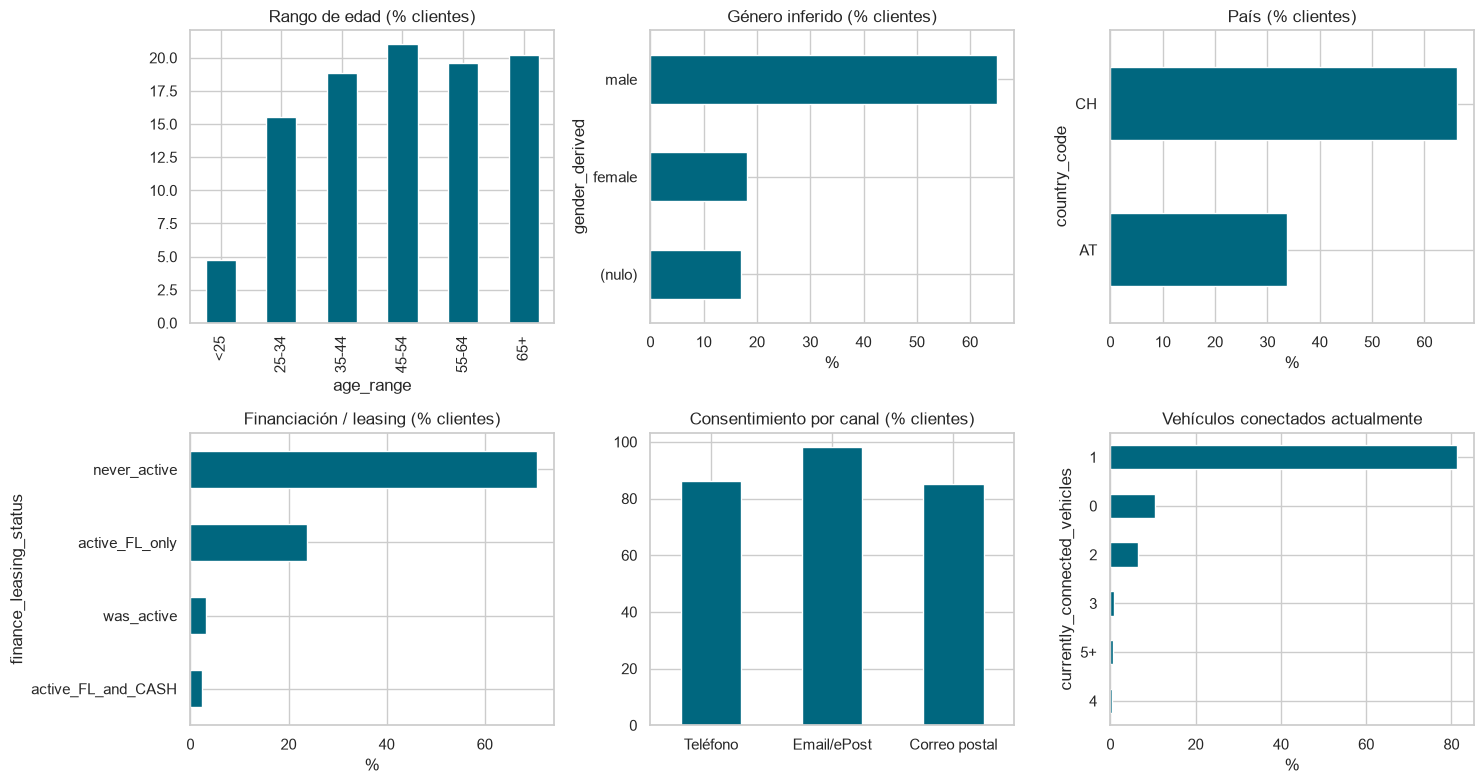

In [21]:
def barras(ax, s, titulo, top=None):
    vc = s.fillna("(nulo)").value_counts(normalize=True).mul(100)
    if top:
        vc = vc.head(top)
    vc.plot.barh(ax=ax, color="#00677F")
    ax.invert_yaxis()
    ax.set(title=titulo, xlabel="%")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
orden_edad = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]
clientes["age_range"].value_counts(normalize=True).mul(100).reindex(orden_edad).plot.bar(ax=axes[0, 0], color="#00677F", title="Rango de edad (% clientes)")
barras(axes[0, 1], clientes["gender_derived"], "Género inferido (% clientes)")
barras(axes[0, 2], clientes["country_code"], "País (% clientes)")
barras(axes[1, 0], clientes["finance_leasing_status"], "Financiación / leasing (% clientes)")
consent = clientes[["consent_phone_communication_channel", "consent_epost_communication_channel",
                    "consent_post_communication_channel"]].mean().mul(100)
consent.index = ["Teléfono", "Email/ePost", "Correo postal"]
consent.plot.bar(ax=axes[1, 1], color="#00677F", title="Consentimiento por canal (% clientes)", rot=0)
barras(axes[1, 2], clientes["currently_connected_vehicles"].clip(upper=5).astype(str).replace("5", "5+"), "Vehículos conectados actualmente")
plt.tight_layout()
plt.show()

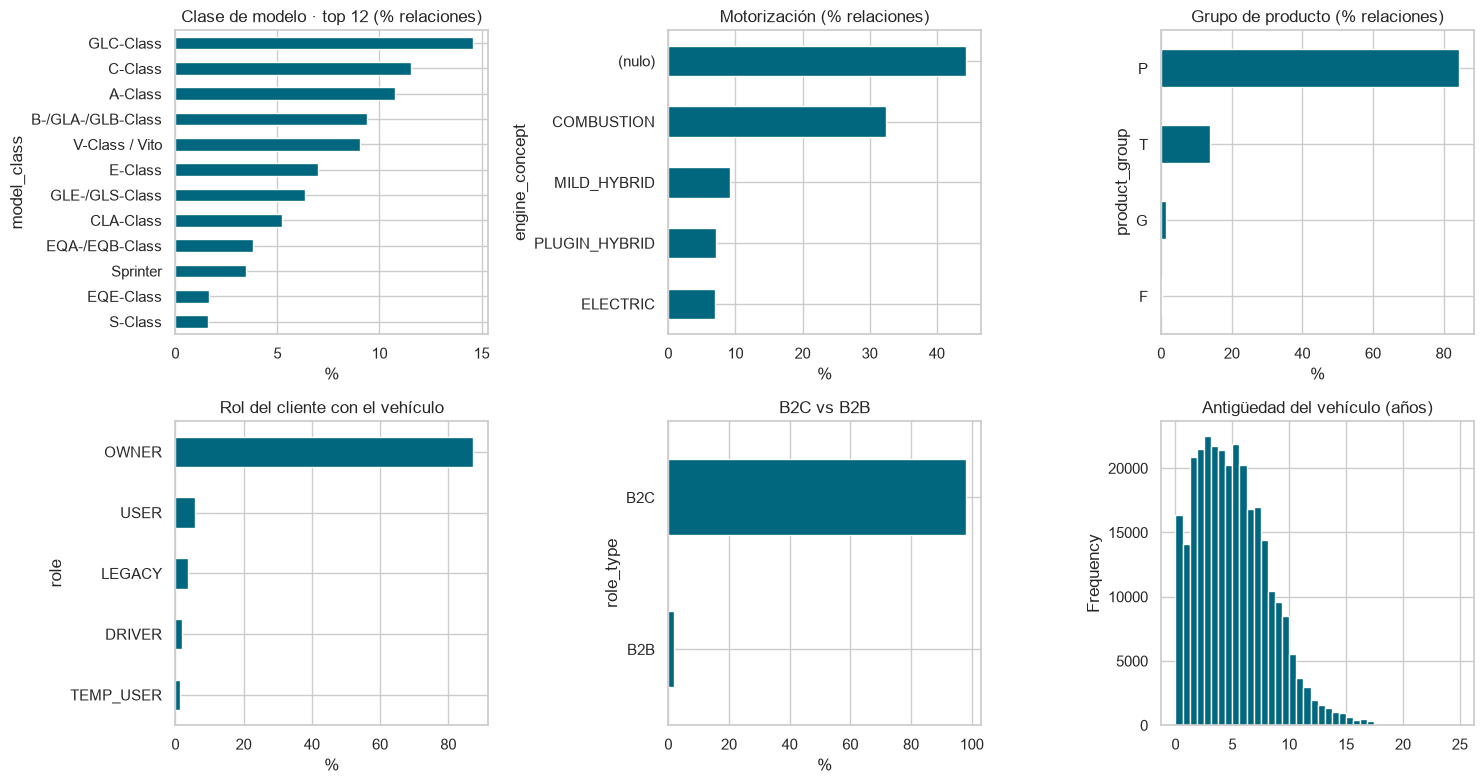

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
barras(axes[0, 0], df["model_class"], "Clase de modelo · top 12 (% relaciones)", top=12)
barras(axes[0, 1], df["engine_concept"], "Motorización (% relaciones)")
barras(axes[0, 2], df["product_group"], "Grupo de producto (% relaciones)")
barras(axes[1, 0], df["role"], "Rol del cliente con el vehículo")
barras(axes[1, 1], df["role_type"], "B2C vs B2B")
edad_veh = (FECHA_REF - reg).dt.days / 365.25
edad_veh.plot.hist(ax=axes[1, 2], bins=40, range=(0, 25), color="#00677F", title="Antigüedad del vehículo (años)")
plt.tight_layout()
plt.show()

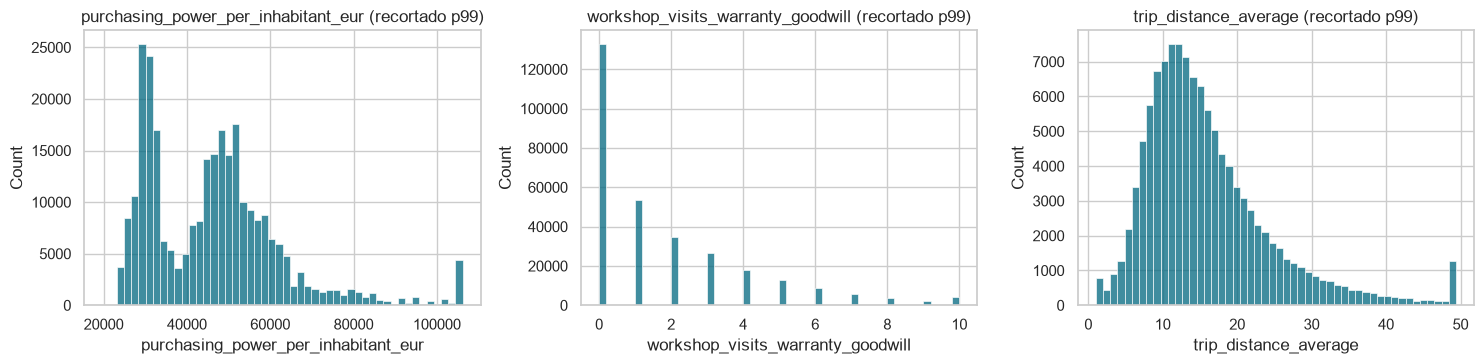

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axes, ["purchasing_power_per_inhabitant_eur", "workshop_visits_warranty_goodwill", "trip_distance_average"]):
    sns.histplot(df[c].dropna().clip(upper=df[c].quantile(.99)), bins=50, ax=ax, color="#00677F")
    ax.set(title=c + " (recortado p99)")
plt.tight_layout()
plt.show()

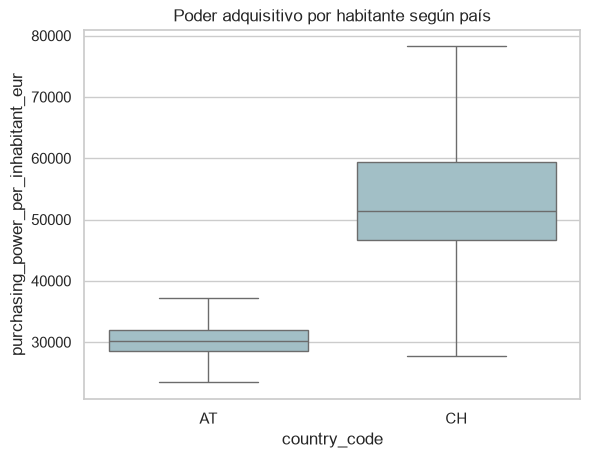

In [24]:
# Poder adquisitivo por país: ¿hay que normalizar dentro de cada país?
sns.boxplot(data=clientes, x="country_code", y="purchasing_power_per_inhabitant_eur", showfliers=False, color="#9cc3cc")
plt.title("Poder adquisitivo por habitante según país")
plt.show()

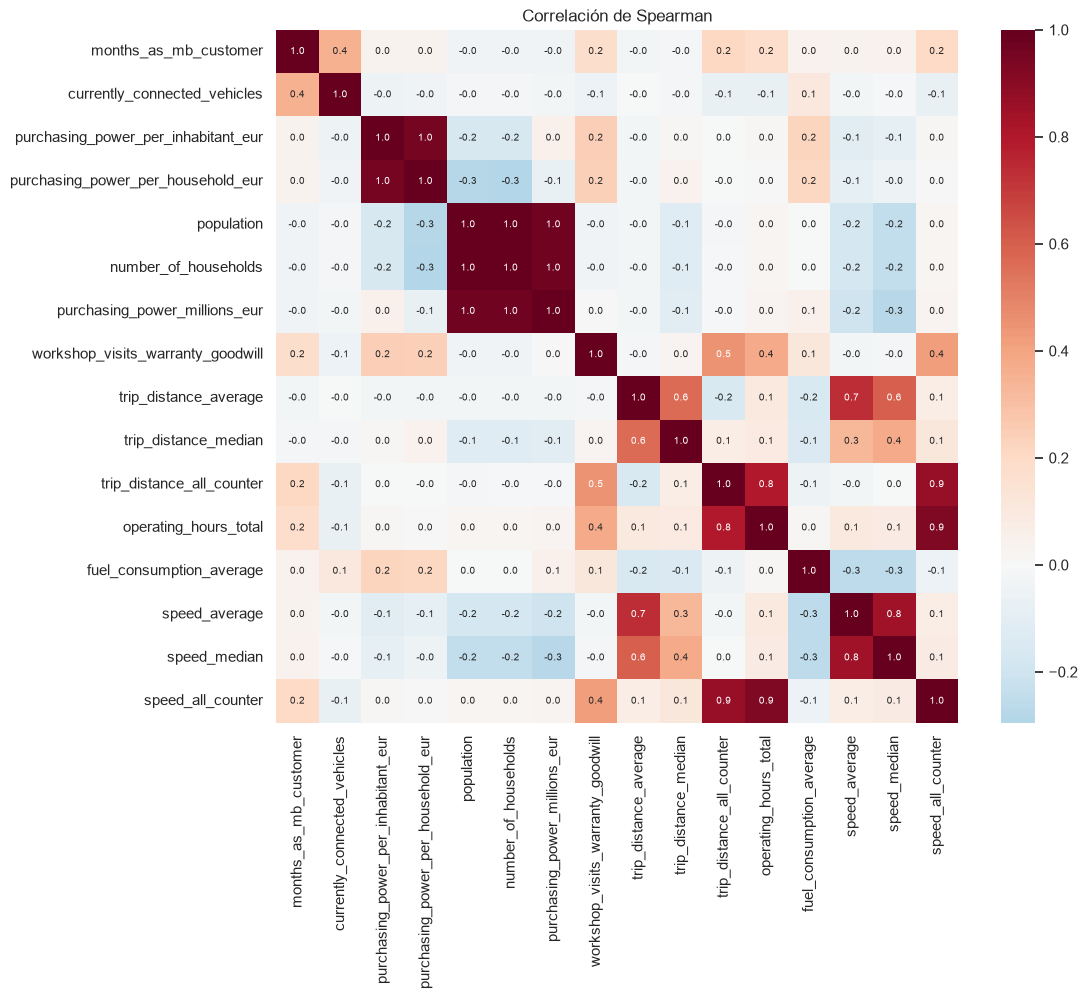

In [25]:
# Correlación entre variables numéricas (una fila por relación)
corr = df[num_cliente + num_vehiculo].corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlación de Spearman")
plt.show()

## 6. Propuesta de tratamiento de calidad

| Problema | Alcance | Tratamiento propuesto |
|---|---|---|
| Granularidad cliente–vehículo | 302.850 filas · 173.456 clientes | Agregar a **1 fila por cliente** en el Reto 2 (los atributos de cliente son 100 % consistentes entre filas) |
| Clientes "tipo flota" | 1.706 clientes (1 %) acumulan el 20 % de las filas; máx. 561 | Al agregar por cliente pesan 1 fila cada uno; usar nº de vehículos con **transformación logarítmica** o recortado para que no dominen K-Means |
| Telemetría ~60 % nula, en bloque | Sobre todo vehículos pasados o no conectados | **No imputar**. Feature binaria *tiene vehículo conectado*; métricas de conducción solo para **perfilar** clusters |
| Outliers de telemetría | 401 filas con consumo > 30, 10 con velocidad > 200 km/h | Irrelevante para el modelo (no entra); para perfilar usar **medianas** |
| `engine_concept` / `fuel_type` nulos | 44 % / 59 % | `engine_concept` es más completo y coherente con `fuel_type` (ver tabla cruzada) → usar solo `engine_concept`, con categoría explícita `UNKNOWN` |
| `gender_derived` nulo | 17 % de clientes | Categoría `unknown` (es una variable inferida; el nulo es informativo) |
| `model_class` nulo | 1,1 % | Son **modelos nuevos** (GLC 400 4MATIC, GLB 350, CLA 220…) → rellenar a partir del prefijo de `vehicle_type` |
| Socioeconómicos nulos | 6,3 % | Imputar con la **mediana del país** |
| `population` = 0 con poder adquisitivo | 73 filas | Irrelevante: `population` no se usará como feature |
| `date_of_first_registration` nulo | 1,4 % | Antigüedad del vehículo imputada con la mediana |
| `months_as_mb_customer` nulo | 4 filas | Imputar con la mediana |
| Socioeconómicos muy correlacionados entre sí | ρ ≈ 1 entre poder adquisitivo por habitante y por hogar; población ≈ hogares ≈ poder total | Usar **una sola** variable de poder adquisitivo |
| Poder adquisitivo muy distinto entre países | Mediana AT ≈ 30 k€ vs CH ≈ 51 k€ | Riesgo de que los clusters separen solo por país → valorar normalizar **dentro de cada país** |
| Consentimiento email casi universal | 98 % | Apenas discrimina; teléfono y correo postal sí aportan |
| Columnas de identificadores / metadatos | 9 columnas | Excluir (tabla del apartado 2) |

## 7. Resumen de hallazgos

**¿Cómo son los clientes?**
- **173.456 clientes** de **Suiza (66 %)** y **Austria (34 %)**, con 302.850 relaciones cliente–vehículo.
- Perfil **maduro**: el 61 % tiene 45 años o más; el tramo más numeroso es 45-54. Los menores de 25 son menos del 4 %.
- Mayoría **masculina** (65 % hombre, 18 % mujer y 17 % sin dato; el género es inferido).
- Relación **reciente** con la marca: mediana de 36 meses como cliente. Casi todos tienen **un vehículo conectado**
  (mediana 1), pero un 10 % no tiene ninguno activo, es decir, son **ex-clientes o clientes "dormidos"**.
- El 27 % ha tenido más de un Mercedes, y existe un núcleo de ~1.700 clientes con comportamiento de **flota**.
- Casi todo es **particular (B2C)**; solo el 1,8 % de las relaciones son B2B.
- El **29 %** ha usado alguna vez **financiación o leasing**.
- Gama: dominan **turismos** (84 %), con C, GLC, A y E-Class a la cabeza. **1 de cada 4** vehículos con motorización
  conocida es **electrificado** (PHEV o BEV).
- Zonas de **alto poder adquisitivo** (mediana ~47 k€ por habitante), sobre todo en CH.
- Consentimiento de email prácticamente universal (98 %); teléfono y correo postal son los canales que diferencian.

**Problemas de calidad y solución** (detalle en la tabla del apartado 6):
granularidad por relación → agregación por cliente; telemetría ausente en ~60 % → flag + solo perfilado;
nulos de motorización → `engine_concept` con categoría `UNKNOWN`; `model_class` de modelos nuevos → relleno por nombre;
socioeconómicos → mediana por país; redundancias → una sola variable de poder adquisitivo;
identificadores y metadatos → excluidos.

In [26]:
resumen = {
    "clientes": n_clients,
    "relaciones cliente-vehículo": n_rows,
    "% clientes CH": (clientes["country_code"] == "CH").mean() * 100,
    "% clientes hombres (inferido)": (clientes["gender_derived"] == "male").mean() * 100,
    "% clientes 45+": clientes["age_range"].isin(["45-54", "55-64", "65+"]).mean() * 100,
    "% clientes con >1 vehículo en el histórico": (veh_por_cliente > 1).mean() * 100,
    "% clientes con financiación/leasing alguna vez": (clientes["finance_leasing_status"] != "never_active").mean() * 100,
    "% relaciones B2B": (df["role_type"] == "B2B").mean() * 100,
    "% relaciones electrificadas (PHEV+BEV, sobre conocidas)": df["engine_concept"].isin(["PLUGIN_HYBRID", "ELECTRIC"]).sum() / df["engine_concept"].notna().sum() * 100,
    "% relaciones con telemetría": df["tiene_telemetria"].mean() * 100,
    "% clientes consentimiento email": clientes["consent_epost_communication_channel"].mean() * 100,
    "% clientes sin vehículo conectado actualmente": (clientes["currently_connected_vehicles"] == 0).mean() * 100,
}
pd.Series(resumen).round(1)

clientes                                                  173,456.00
relaciones cliente-vehículo                               302,850.00
% clientes CH                                                  66.20
% clientes hombres (inferido)                                  65.00
% clientes 45+                                                 60.80
% clientes con >1 vehículo en el histórico                     26.70
% clientes con financiación/leasing alguna vez                 29.40
% relaciones B2B                                                1.80
% relaciones electrificadas (PHEV+BEV, sobre conocidas)        25.10
% relaciones con telemetría                                    48.20
% clientes consentimiento email                                98.30
% clientes sin vehículo conectado actualmente                  10.40
dtype: float64